In [1]:
import pickle
from dreems.utils.utility import dreems_infer_genotypes_timing

with open("wolves_data.pkl", "rb") as f:
    loaded = pickle.load(f)

genotypes = loaded["genotypes"]
edges = loaded["edges"]
nodes = loaded["grid"]
coord = loaded["coord"]

surface, timing = dreems_infer_genotypes_timing(genotypes, coord, nodes, edges-1)

Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/home/jkliang/drem/dreems/.venv/lib/python3.11/site-packages/jax/_src/xla_bridge.py", line 508, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/home/jkliang/drem/dreems/.venv/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 370, in initialize
    _check_cuda_versions(raise_on_first_error = True)
  File "/home/jkliang/drem/dreems/.venv/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 274, in _check_cuda_versions
    for d in range(cuda_versions.cuda_device_count())
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:135: operation cuInit(0) failed: Unknown CUDA error 303; cuGetErrorName failed. This probably means that JAX was unable to load the CUDA libraries.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed.

{"conditioner_failure_examples": [], "conditioner_failures": 0, "conditioner_observed_nodes_mean": 94.0, "conditioner_observed_pairs_mean": 4371.0, "conditioner_seconds_total": 0.3175628399476409, "edge_conditioner": "linearized_resistance", "edge_conditioner_methods": ["all_pair_diagonal_adjoint"], "edge_dim_after": 253, "edge_dim_before": 251, "examples": 1, "stage": "append_edge_conditioner_features"}


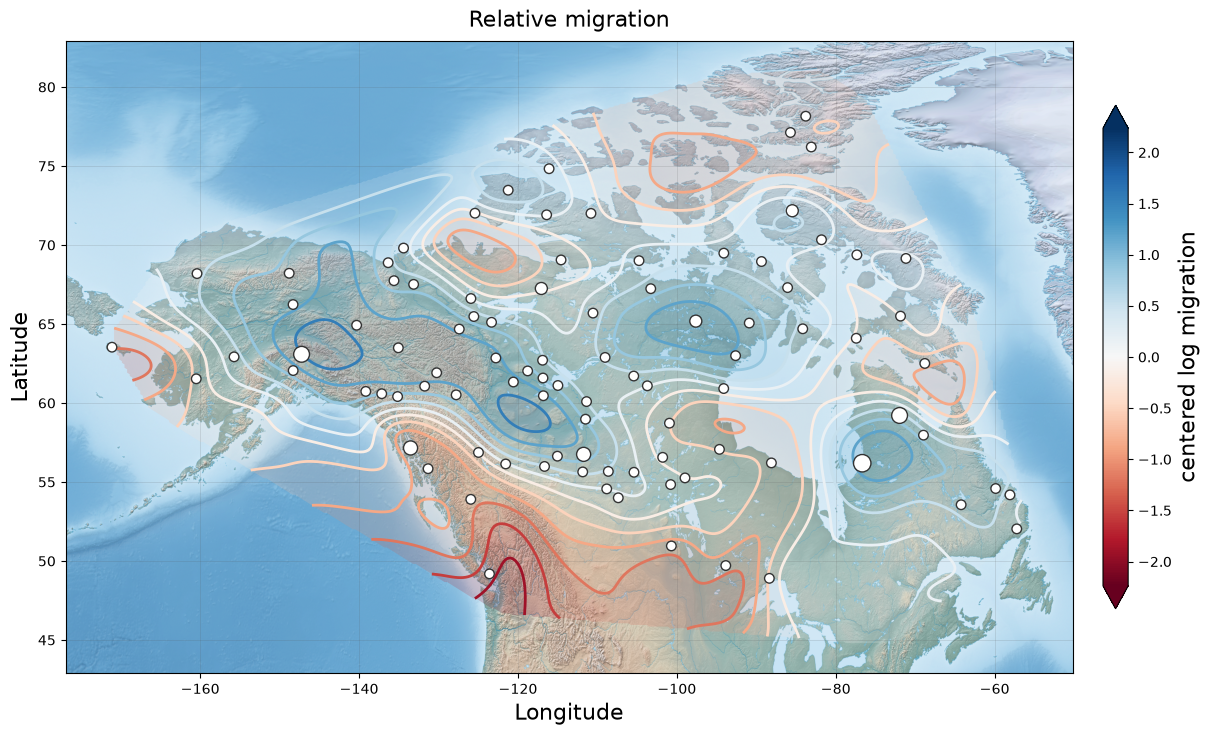

In [2]:
from dreems.utils.snakemake_plot import draw_figure_map

fig, ax = draw_figure_map(
    surface,
    sample_to_pop=None,
    smoothing_sigma=5.0,
    contour_levels=14,
    contour_linewidth=2.0,
    contour_fill_alpha=0.20,
    # figure_path="./dreems_wolves_relative_posterior_map.pdf",
    # posterior=True
)

In [6]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import rasterio

from collections import Counter
from matplotlib.colors import Normalize, TwoSlopeNorm
from rasterio.plot import show
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter


def edge_values_to_node_values(
    number_of_nodes,
    edge_nodes,
    edge_values,
):
    """
    Average edge-level values onto their incident nodes.
    """
    edge_nodes = np.asarray(edge_nodes, dtype=int)
    edge_values = np.asarray(edge_values, dtype=np.float64)

    if len(edge_values) != len(edge_nodes):
        raise ValueError(
            "There must be exactly one value for every edge"
        )

    node_sums = np.zeros(
        number_of_nodes,
        dtype=np.float64,
    )

    node_counts = np.zeros(
        number_of_nodes,
        dtype=np.float64,
    )

    # Add each edge value to both endpoint nodes.
    np.add.at(
        node_sums,
        edge_nodes[:, 0],
        edge_values,
    )
    np.add.at(
        node_sums,
        edge_nodes[:, 1],
        edge_values,
    )

    np.add.at(
        node_counts,
        edge_nodes[:, 0],
        1.0,
    )
    np.add.at(
        node_counts,
        edge_nodes[:, 1],
        1.0,
    )

    node_values = np.full(
        number_of_nodes,
        np.nan,
        dtype=np.float64,
    )

    valid_nodes = node_counts > 0

    node_values[valid_nodes] = (
        node_sums[valid_nodes]
        / node_counts[valid_nodes]
    )

    return node_values


def generalized_contour_surface(
    longitude,
    latitude,
    node_values,
    *,
    grid_size=350,
    smoothing_sigma=20.0,
):
    """
    Interpolate node values over a longitude/latitude grid and smooth
    the resulting surface.

    Parameters
    ----------
    longitude
        Node longitudes in decimal degrees.
    latitude
        Node latitudes in decimal degrees.
    node_values
        Scalar value assigned to each node.
    grid_size
        Number of interpolation cells in each dimension.
    smoothing_sigma
        Gaussian smoothing measured in grid cells. Larger values
        produce broader and more generalized contours.
    """
    longitude = np.asarray(
        longitude,
        dtype=np.float64,
    )

    latitude = np.asarray(
        latitude,
        dtype=np.float64,
    )

    node_values = np.asarray(
        node_values,
        dtype=np.float64,
    )

    valid_nodes = (
        np.isfinite(longitude)
        & np.isfinite(latitude)
        & np.isfinite(node_values)
    )

    interpolation_positions = np.column_stack(
        (
            longitude[valid_nodes],
            latitude[valid_nodes],
        )
    )

    interpolation_values = node_values[valid_nodes]

    if len(interpolation_values) < 3:
        raise ValueError(
            "At least three nodes with finite values are "
            "required to construct contours."
        )

    longitude_values = np.linspace(
        longitude.min(),
        longitude.max(),
        grid_size,
    )

    latitude_values = np.linspace(
        latitude.min(),
        latitude.max(),
        grid_size,
    )

    grid_longitude, grid_latitude = np.meshgrid(
        longitude_values,
        latitude_values,
    )

    interpolated_values = griddata(
        points=interpolation_positions,
        values=interpolation_values,
        xi=(grid_longitude, grid_latitude),
        method="linear",
        fill_value=np.nan,
    )

    valid_grid = np.isfinite(interpolated_values)

    # NaN-aware Gaussian smoothing.
    numerator = gaussian_filter(
        np.where(
            valid_grid,
            interpolated_values,
            0.0,
        ),
        sigma=smoothing_sigma,
        mode="nearest",
    )

    denominator = gaussian_filter(
        valid_grid.astype(np.float64),
        sigma=smoothing_sigma,
        mode="nearest",
    )

    smoothed_values = np.full_like(
        interpolated_values,
        np.nan,
    )

    usable = valid_grid & (denominator > 1.0e-12)

    smoothed_values[usable] = (
        numerator[usable]
        / denominator[usable]
    )

    return (
        grid_longitude,
        grid_latitude,
        smoothed_values,
    )


def draw_figure_map(
    surface,
    sample_to_pop=None,
    raster_path=(
        "/home/jkliang/dreems/KL_code/"
        "final_paper_figures/HYP_HR_SR_OB_DR/"
        "HYP_HR_SR_OB_DR.tif"
    ),
    limit=1.0,
    contour_levels=9,
    contour_linewidth=2.0,
    contour_fill_alpha=0.20,
    contour_line_alpha=1.0,
    smoothing_sigma=20.0,
    grid_size=350,
    map_padding_fraction=0.05,
    basemap_alpha=1.0,
    show_contour_fill=True,
    show_contour_lines=True,
    show_axes=True,
    save_figure=False,
    posterior=False,
    figure_path=None,
):
    """
    Plot generalized contours over a longitude/latitude raster map.

    The following variables must use the same longitude/latitude
    coordinate system as the raster:

        surface["node_longitude"]
        surface["node_latitude"]

    Parameters
    ----------
    smoothing_sigma
        Gaussian smoothing in grid cells. Values around 15-35 produce
        broadly generalized contours.

    contour_levels
        Number of contour boundaries. Values around 7-11 usually
        produce large, readable contour regions.
    """

    # 1. LONGITUDE AND LATITUDE
    longitude = np.asarray(
        surface["node_position"].values[:,0],
        dtype=np.float64,
    )

    latitude = np.asarray(
        surface["node_position"].values[:,1],
        dtype=np.float64,
    )

    if longitude.ndim != 1 or latitude.ndim != 1:
        raise ValueError(
            "node_longitude and node_latitude must be "
            "one-dimensional arrays"
        )

    if len(longitude) != len(latitude):
        raise ValueError(
            "node_longitude and node_latitude must have "
            "the same length"
        )

    positions = np.column_stack(
        (longitude, latitude)
    )

    edge_nodes = np.asarray(
        surface["edge_node"].values,
        dtype=int,
    )

    edge_log_migration = np.asarray(
        surface["edge_log_migration_refined"].values,
        dtype=np.float64,
    )

    edge_log_sd = np.asarray(
        surface["edge_log_migration_sd"].values,
        dtype=np.float64,
    )

    sample_count = np.asarray(
        surface["node_sample_count"].values,
    )

    # 2. POPULATION COLORS
    node_colors = []
    pop_color_map = {}

    if sample_to_pop is not None:
        unique_populations = sorted(
            set(sample_to_pop.values())
        )

        population_cmap = mpl.colormaps[
            "tab10"
        ].resampled(len(unique_populations))

        pop_color_map = {
            population: population_cmap(index)
            for index, population in enumerate(
                unique_populations
            )
        }

        sample_ids = surface["sample_id"].values
        sample_nodes = surface["sample_nodes"].values

        node_to_samples = {
            node_index: []
            for node_index in range(len(sample_count))
        }

        for sample_id, node_index in zip(
            sample_ids,
            sample_nodes,
        ):
            node_to_samples[int(node_index)].append(
                sample_id
            )

        for node_index, count in enumerate(sample_count):
            if count <= 0:
                continue

            populations = [
                sample_to_pop[sample_id]
                for sample_id
                in node_to_samples[node_index]
                if sample_id in sample_to_pop
            ]

            if populations:
                majority_population = Counter(
                    populations
                ).most_common(1)[0][0]

                node_colors.append(
                    pop_color_map[majority_population]
                )
            else:
                node_colors.append("white")

    else:
        node_colors = [
            "white"
        ] * int(np.sum(sample_count > 0))

    # 3. CONTOUR CONFIGURATION
    if posterior:
        edge_values = edge_log_sd

        value_limit = max(
            float(np.nanmax(edge_values)),
            0.1,
        ) * limit

        color_norm = Normalize(
            vmin=0.0,
            vmax=value_limit,
        )

        contour_values = np.linspace(
            0.0,
            value_limit,
            contour_levels,
        )

        color_map = "magma"
        colorbar_extend = "max"
        title = "Posterior uncertainty"
        colorbar_label = "posterior SD"

    else:
        edge_values = edge_log_migration

        value_limit = max(
            float(np.nanmax(np.abs(edge_values))),
            0.1,
        ) * limit

        color_norm = TwoSlopeNorm(
            vmin=-value_limit,
            vcenter=0.0,
            vmax=value_limit,
        )

        contour_values = np.linspace(
            -value_limit,
            value_limit,
            contour_levels,
        )

        color_map = "RdBu"
        colorbar_extend = "both"
        title = "Relative migration"
        colorbar_label = "centered edge log migration"

    # 4. GENERALIZED CONTOUR SURFACE
    node_values = edge_values_to_node_values(
        number_of_nodes=len(longitude),
        edge_nodes=edge_nodes,
        edge_values=edge_values,
    )

    (
        grid_longitude,
        grid_latitude,
        grid_values,
    ) = generalized_contour_surface(
        longitude=longitude,
        latitude=latitude,
        node_values=node_values,
        grid_size=grid_size,
        smoothing_sigma=smoothing_sigma,
    )

    # 5. OPEN AND VALIDATE RASTER
    with rasterio.open(raster_path) as raster:
        if (
            raster.crs is not None
            and not raster.crs.is_geographic
        ):
            raise ValueError(
                "The raster must use a geographic longitude/"
                "latitude CRS. Its current CRS is "
                f"{raster.crs!s}."
            )

        # 6. FIGURE AND RASTER BACKGROUND
        fig, ax = plt.subplots(
            figsize=(12, 10),
            constrained_layout=True,
        )

        show(
            raster,
            ax=ax,
            alpha=basemap_alpha,
            zorder=0,
        )

        longitude_min = float(longitude.min())
        longitude_max = float(longitude.max())
        latitude_min = float(latitude.min())
        latitude_max = float(latitude.max())

        longitude_range = (
            longitude_max - longitude_min
        )

        latitude_range = (
            latitude_max - latitude_min
        )

        longitude_padding = (
            longitude_range * map_padding_fraction
            if longitude_range > 0
            else 0.1
        )

        latitude_padding = (
            latitude_range * map_padding_fraction
            if latitude_range > 0
            else 0.1
        )

        ax.set_xlim(
            longitude_min - longitude_padding,
            longitude_max + longitude_padding,
        )

        ax.set_ylim(
            latitude_min - latitude_padding,
            latitude_max + latitude_padding,
        )

        # 7. FILLED CONTOURS
        if show_contour_fill:
            ax.contourf(
                grid_longitude,
                grid_latitude,
                grid_values,
                levels=contour_values,
                cmap=color_map,
                norm=color_norm,
                alpha=contour_fill_alpha,
                extend=colorbar_extend,
                antialiased=True,
                zorder=1,
            )

        # 8. CONTOUR LINES
        if show_contour_lines:
            ax.contour(
                grid_longitude,
                grid_latitude,
                grid_values,
                levels=contour_values,
                cmap=color_map,
                norm=color_norm,
                linewidths=contour_linewidth,
                alpha=contour_line_alpha,
                zorder=2,
            )

        # 9. FULLY OPAQUE COLORBAR

        colorbar_mappable = mpl.cm.ScalarMappable(
            norm=color_norm,
            cmap=mpl.colormaps[color_map],
        )

        colorbar_mappable.set_array([])

        cbar = fig.colorbar(
            colorbar_mappable,
            ax=ax,
            label=colorbar_label,
            fraction=0.025,
            pad=0.03,
            shrink=0.75,
            extend=colorbar_extend,
        )

        cbar.set_alpha(1.0)

        if cbar.solids is not None:
            cbar.solids.set_alpha(1.0)

        # 10. SAMPLE NODES
        occupied_nodes = sample_count > 0
        occupied_positions = positions[occupied_nodes]
        occupied_counts = sample_count[occupied_nodes]

        ax.scatter(
            occupied_positions[:, 0],
            occupied_positions[:, 1],
            s=20.0 + 25.0 * occupied_counts,
            c=node_colors,
            edgecolor="#333333",
            linewidth=1.0,
            zorder=4,
        )

        # 11. POPULATION LEGEND
        if sample_to_pop is not None and pop_color_map:
            legend_elements = [
                plt.Line2D(
                    [0],
                    [0],
                    marker="o",
                    linestyle="none",
                    label=population,
                    markerfacecolor=color,
                    markeredgecolor="#333333",
                    markersize=8,
                )
                for population, color
                in pop_color_map.items()
            ]

            ax.legend(
                handles=legend_elements,
                title="Populations",
                loc="lower right",
                frameon=True,
                framealpha=0.9,
            )

        # 12. MAP FORMATTING
        mean_latitude = float(np.mean(latitude))

        # Approximate correction so longitude and latitude are shown
        # with a geographically reasonable aspect ratio.
        aspect = 1.0 / np.cos(
            np.deg2rad(mean_latitude)
        )

        ax.set_aspect(aspect)
        ax.set_title(title, fontsize=13, pad=10)

        if show_axes:
            ax.set_xlabel("Longitude")
            ax.set_ylabel("Latitude")

            ax.grid(
                color="#555555",
                linewidth=0.4,
                alpha=0.25,
            )
        else:
            ax.set_axis_off()
            
        if save_figure:
            if figure_path is None:
                raise ValueError(
                    "figure_path is required when "
                    "save_figure=True"
                )

            fig.savefig(
                figure_path,
                bbox_inches="tight",
                dpi=300,
            )

        plt.show()

    return fig, ax

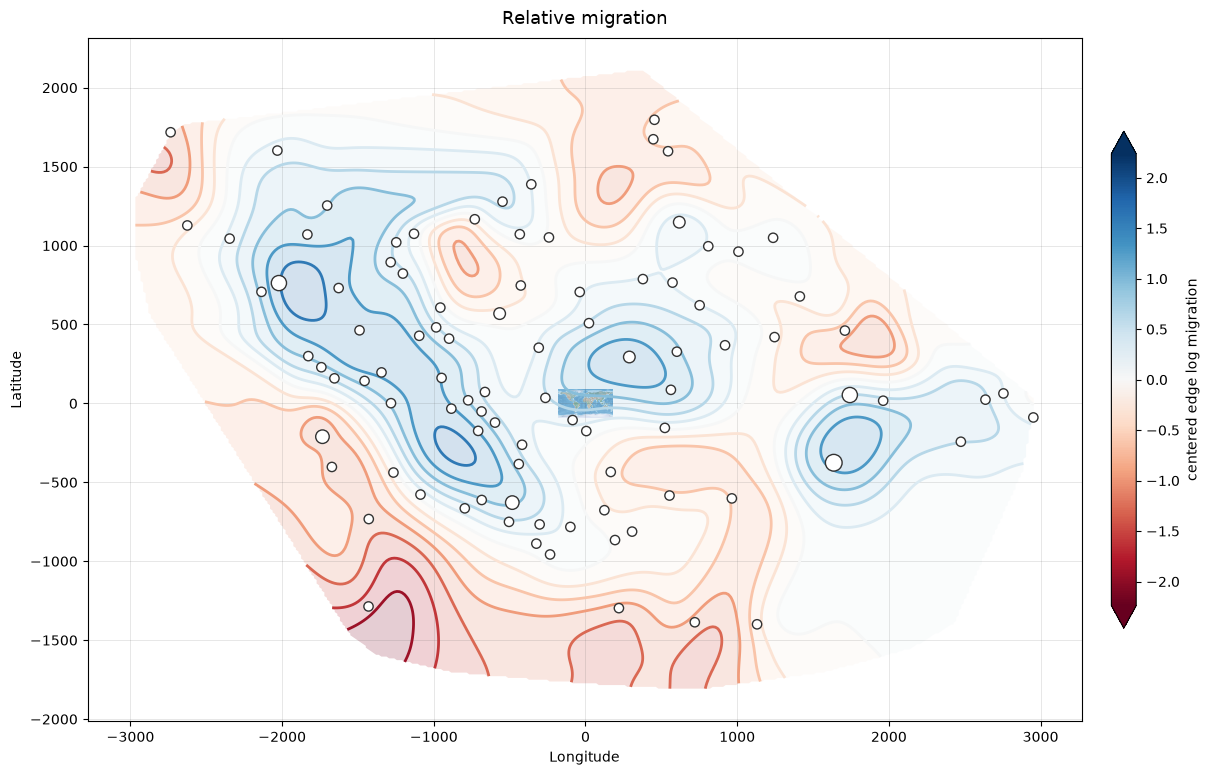

In [7]:
fig, ax = draw_figure_map(
    surface,
    sample_to_pop=None,
    smoothing_sigma=5,
    contour_levels=15,
    contour_linewidth=2.0,
    contour_fill_alpha=0.20,
    save_figure=False,
    # figure_path="./dreems_wolves_relative_posterior_map.pdf",
    posterior=False
)